In [10]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [13]:
# =========================
# CONFIG
# =========================
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
#AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2.csv"
AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2_4class.csv"
TRANSLATED_CN_PATH = "/content/drive/MyDrive/conversation_cn_translated_en_deepseek_v4flash.json"

RESULTS_DIR = "/content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew"
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN = 256
RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]
label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3}
id2label = {v: k for k, v in label2id.items()}

print("Labels:", label2id)
print("LR:", LEARNING_RATE, "weight_decay:", WEIGHT_DECAY)

Labels: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3}
LR: 2e-05 weight_decay: 0.01


In [14]:
# =========================
# LOAD ORIGINAL ENGLISH DATA
# =========================
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Original full turn rows:", len(df_turns_full))
print("Original 4-class target rows:", len(target_df))
print("Original conversations:", target_df["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Original full turn rows: 5633
Original 4-class target rows: 3179
Original conversations: 825
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [15]:
# =========================
#  GROUPED SINGLE SPLIT
# =========================
gss1 = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(
    n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df_original = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

train_cids = set(train_df_original["conversation_id"].astype(str))
val_cids = set(val_df["conversation_id"].astype(str))
test_cids = set(test_df["conversation_id"].astype(str))

print("Original train rows:", len(train_df_original))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Train ∩ Val:", len(train_cids & val_cids))
print("Train ∩ Test:", len(train_cids & test_cids))
print("Val ∩ Test:", len(val_cids & test_cids))

assert train_cids.isdisjoint(val_cids)
assert train_cids.isdisjoint(test_cids)
assert val_cids.isdisjoint(test_cids)

#4class original english data split
assert len(train_df_original) == 2014, f"Unexpected train rows: {len(train_df_original)}"
assert len(val_df) == 503, f"Unexpected val rows: {len(val_df)}"
assert len(test_df) == 662, f"Unexpected test rows: {len(test_df)}"



Original train rows: 2014
Validation rows: 503
Test rows: 662
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [16]:
# =========================
# LLM AUGMENTATION TRAIN DATA ONLY
# =========================
aug_all_df = pd.read_csv(AUGMENTED_TRAIN_PATH)

required_aug_columns = {
    "conversation_id", "turn_index", "role", "text", "intent", "is_augmented"
}
missing_columns = required_aug_columns - set(aug_all_df.columns)
assert not missing_columns, f"Missing augmentation columns: {missing_columns}"

aug_all_df["conversation_id"] = aug_all_df["conversation_id"].astype(str)
aug_all_df["turn_index"] = pd.to_numeric(
    aug_all_df["turn_index"], errors="raise"
).astype(int)
aug_all_df["role"] = (
    aug_all_df["role"].fillna("").astype(str).str.strip().str.lower()
)
aug_all_df["text"] = aug_all_df["text"].fillna("").astype(str)
aug_all_df["intent"] = (
    aug_all_df["intent"].fillna("").astype(str).str.strip()
)

is_genuine_augmentation = (
    aug_all_df["is_augmented"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "1.0"])
)

aug_genuine_df = aug_all_df[
    is_genuine_augmentation
    & (aug_all_df["role"] == "user")
    & (aug_all_df["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

assert len(aug_genuine_df) > 0, (
    "No genuine augmented rows found. Check the is_augmented column."
)

#synthetic row may enter training only if its source English conversation is in the original train data
aug_train_df = aug_genuine_df[
    aug_genuine_df["conversation_id"].isin(train_cids)
].copy().reset_index(drop=True)

aug_cids = set(aug_train_df["conversation_id"].astype(str))

print("Rows in augmentation CSV:", len(aug_all_df))
print("Original/non-augmented rows excluded:", int((~is_genuine_augmentation).sum()))
print("valid 4-class augmentation rows:", len(aug_genuine_df))
print("Train-source genuine augmentation kept:", len(aug_train_df))
print("Valid augmentation rows excluded because source was not TRAIN:",
    len(aug_genuine_df) - len(aug_train_df),
)
print("Aug source ∩ Val:", len(aug_cids & val_cids))
print("Aug source ∩ Test:", len(aug_cids & test_cids))
print("Aug source outside Train:", len(aug_cids - train_cids))

assert aug_cids.isdisjoint(val_cids), (
    "LEAKAGE: validation-source augmentation entered training."
)
assert aug_cids.isdisjoint(test_cids), (
    "LEAKAGE: test-source augmentation entered training."
)
assert aug_cids.issubset(train_cids), (
    "Unexpected augmentation source outside original training split."
)

# Verify every synthetic row maps to an original 4-class TRAIN source turn
source_4class = train_df_original[
    ["conversation_id", "turn_index", "intent"]
].copy()
source_4class["conversation_id"] = source_4class["conversation_id"].astype(str)
source_4class["turn_index"] = source_4class["turn_index"].astype(int)

aug_source_check = aug_train_df.merge(
    source_4class,
    on=["conversation_id", "turn_index"],
    how="left",
    suffixes=("_aug", "_source"),
)

missing_source_turns = int(aug_source_check["intent_source"].isna().sum())
changed_labels = int((
    aug_source_check["intent_source"].notna()
    & (aug_source_check["intent_aug"] != aug_source_check["intent_source"])
).sum())

print("Augmented rows missing original TRAIN source turn:", missing_source_turns)
print("Augmented rows with changed labels:", changed_labels)

assert missing_source_turns == 0
assert changed_labels == 0

Rows in augmentation CSV: 2214
Original/non-augmented rows excluded: 2014
valid 4-class augmentation rows: 200
Train-source genuine augmentation kept: 200
Valid augmentation rows excluded because source was not TRAIN: 0
Aug source ∩ Val: 0
Aug source ∩ Test: 0
Aug source outside Train: 0
Augmented rows missing original TRAIN source turn: 0
Augmented rows with changed labels: 0


In [17]:
# =========================
# LOAD TRANSLATED CHINESE DATA — INDEPENDENT EXTERNAL TRAINING CORPUS so no removal
# =========================

with open(TRANSLATED_CN_PATH, "r", encoding="utf-8") as f:
    cn_raw = json.load(f)

cn_rows = []
for conv in cn_raw:
    cid = "CN_" + str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        cn_rows.append({
            "conversation_id": cid,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

cn_turns_full = pd.DataFrame(cn_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)
cn_turns_full["conversation_id"] = cn_turns_full["conversation_id"].astype(str)
cn_turns_full["turn_index"] = cn_turns_full["turn_index"].astype(int)
cn_turns_full["role"] = cn_turns_full["role"].astype(str).str.lower()
cn_turns_full["text"] = cn_turns_full["text"].fillna("").astype(str)

cn_train_df = cn_turns_full[
    (cn_turns_full["role"] == "user") &
    (cn_turns_full["intent"].notna()) &
    (cn_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

print("Independent translated CN 4-class rows retained:", len(cn_train_df))
print("CN rows removed:", 0)

cn_turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in cn_turns_full.groupby("conversation_id")
}
turns_by_conv_full.update(cn_turns_by_conv_full)


Independent translated CN 4-class rows retained: 3055
CN rows removed: 0


In [18]:
# =========================
# FINAL TRAIN + LEAKAGE AUDIT
# =========================
# translated CN is an independent training data so used all no filter
train_df = pd.concat(
    [train_df_original, aug_train_df, cn_train_df],
    ignore_index=True,
).reset_index(drop=True)

print("Final train rows:", len(train_df))
print("  original English:", len(train_df_original))
print("  genuine safe augmentation:", len(aug_train_df))
print("  independent translated CN:", len(cn_train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("\nFinal train label distribution:")
print(train_df["intent"].value_counts())

missing_context_cids = (
    set(train_df["conversation_id"].astype(str)) - set(turns_by_conv_full.keys())
)
print("Missing context conversation IDs:", len(missing_context_cids))
assert len(missing_context_cids) == 0

# Exact text overlap is a diagnostic only. Independent conversations may contain
# identical short utterances; source-conversation isolation is the leakage rule.
def norm_text(x):
    x = str(x).lower().strip()
    x = re.sub(r"\s+", " ", x)
    return x

train_texts = set(train_df["text"].map(norm_text)) - {""}
val_texts = set(val_df["text"].map(norm_text)) - {""}
test_texts = set(test_df["text"].map(norm_text)) - {""}
print("Exact target-text overlap train/val (diagnostic):", len(train_texts & val_texts))
print("Exact target-text overlap train/test (diagnostic):", len(train_texts & test_texts))

audit = pd.DataFrame([{
    "original_train_rows": len(train_df_original),
    "augmentation_csv_rows": len(aug_all_df),
    "genuine_4class_aug_rows": len(aug_genuine_df),
    "safe_train_source_aug_rows": len(aug_train_df),
    "genuine_aug_rows_excluded_nontrain_source": len(aug_genuine_df) - len(aug_train_df),
    "independent_cn_rows": len(cn_train_df),
    "cn_rows_removed": 0,
    "final_train_rows": len(train_df),
    "val_rows": len(val_df),
    "test_rows": len(test_df),
    "train_val_cid_overlap": len(train_cids & val_cids),
    "train_test_cid_overlap": len(train_cids & test_cids),
    "val_test_cid_overlap": len(val_cids & test_cids),
    "aug_val_source_overlap": len(aug_cids & val_cids),
    "aug_test_source_overlap": len(aug_cids & test_cids),
    "aug_missing_source_turns": missing_source_turns,
    "aug_changed_labels": changed_labels,
}])

audit.to_csv(os.path.join(RESULTS_DIR, "leakage_audit.csv"), index=False)
display(audit)


Final train rows: 5269
  original English: 2014
  genuine safe augmentation: 200
  independent translated CN: 3055
Validation rows: 503
Test rows: 662

Final train label distribution:
intent
Interpret    2720
Reveal       1648
Chitchat      551
Revise        350
Name: count, dtype: int64
Missing context conversation IDs: 0
Exact target-text overlap train/val (diagnostic): 53
Exact target-text overlap train/test (diagnostic): 60


,original_train_rows,augmentation_csv_rows,genuine_4class_aug_rows,safe_train_source_aug_rows,genuine_aug_rows_excluded_nontrain_source,independent_cn_rows,cn_rows_removed,final_train_rows,val_rows,test_rows,train_val_cid_overlap,train_test_cid_overlap,val_test_cid_overlap,aug_val_source_overlap,aug_test_source_overlap,aug_missing_source_turns,aug_changed_labels
0,2014,2214,200,200,0,3055,0,5269,503,662,0,0,0,0,0,0,0


In [19]:
# =========================
# SEMANTIC NEAR-DUPLICATE AUDIT
# =========================
#
# Purpose:
#   Reviewer-facing diagnostic for train/validation/test semantic overlap.
#
# Important:
#   This does NOT redefine leakage.
#   Source-conversation isolation remains the primary leakage rule.
#   Here we only flag semantically very similar text pairs for inspection.
#
# Recommended threshold:
#   cosine similarity >= 0.95
#
# Model:
#   sentence-transformers/all-MiniLM-L6-v2
#
# Outputs:
#   semantic_overlap_train_val.csv
#   semantic_overlap_train_test.csv
#   semantic_overlap_summary.csv

!pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd
import torch
import os
import re

SEMANTIC_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
SEMANTIC_THRESHOLD = 0.95

print("Semantic near-duplicate model:", SEMANTIC_MODEL)
print("Cosine-similarity threshold:", SEMANTIC_THRESHOLD)

semantic_model = SentenceTransformer(SEMANTIC_MODEL)


# -------------------------
# NORMALIZE TEXT
# -------------------------

def norm_text_semantic(x):
    x = str(x).lower().strip()
    x = re.sub(r"\s+", " ", x)
    return x


def prepare_semantic_df(df, split_name):
    out = df.copy().reset_index(drop=True)

    out["normalized_text"] = out["text"].map(norm_text_semantic)

    out = out[
        out["normalized_text"].notna()
        & (out["normalized_text"] != "")
    ].copy()

    out["split"] = split_name

    return out.reset_index(drop=True)


semantic_train_df = prepare_semantic_df(train_df, "train")
semantic_val_df = prepare_semantic_df(val_df, "validation")
semantic_test_df = prepare_semantic_df(test_df, "test")

print("Semantic audit rows:")
print("  train:", len(semantic_train_df))
print("  validation:", len(semantic_val_df))
print("  test:", len(semantic_test_df))


# -------------------------
# EMBED TEXT
# -------------------------

train_embeddings = semantic_model.encode(
    semantic_train_df["normalized_text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True,
)

val_embeddings = semantic_model.encode(
    semantic_val_df["normalized_text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True,
)

test_embeddings = semantic_model.encode(
    semantic_test_df["normalized_text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True,
)


# -------------------------
# FIND BEST TRAIN MATCH
# FOR EACH EVALUATION ROW
# -------------------------

def find_semantic_matches(
    train_df_sem,
    eval_df_sem,
    train_emb,
    eval_emb,
    threshold,
    eval_name,
):

    rows = []

    # Since embeddings are normalized,
    # matrix multiplication = cosine similarity.
    similarity_matrix = torch.matmul(
        eval_emb,
        train_emb.T
    )

    best_scores, best_indices = torch.max(
        similarity_matrix,
        dim=1
    )

    best_scores = best_scores.detach().cpu().numpy()
    best_indices = best_indices.detach().cpu().numpy()

    for eval_idx, (score, train_idx) in enumerate(
        zip(best_scores, best_indices)
    ):
        if float(score) < threshold:
            continue

        eval_row = eval_df_sem.iloc[eval_idx]
        train_row = train_df_sem.iloc[int(train_idx)]

        eval_text = eval_row["normalized_text"]
        train_text = train_row["normalized_text"]

        exact_match = (eval_text == train_text)

        rows.append({
            "comparison": f"train_vs_{eval_name}",
            "cosine_similarity": float(score),
            "exact_text_match": bool(exact_match),

            "train_conversation_id": str(
                train_row.get("conversation_id", "")
            ),
            "train_turn_id": str(
                train_row.get("turn_id", "")
            ),
            "train_intent": str(
                train_row.get("intent", "")
            ),
            "train_text": str(
                train_row.get("text", "")
            ),

            f"{eval_name}_conversation_id": str(
                eval_row.get("conversation_id", "")
            ),
            f"{eval_name}_turn_id": str(
                eval_row.get("turn_id", "")
            ),
            f"{eval_name}_intent": str(
                eval_row.get("intent", "")
            ),
            f"{eval_name}_text": str(
                eval_row.get("text", "")
            ),
        })

    matches_df = pd.DataFrame(rows)

    if len(matches_df) > 0:
        matches_df = matches_df.sort_values(
            "cosine_similarity",
            ascending=False
        ).reset_index(drop=True)

    return matches_df


train_val_semantic_matches = find_semantic_matches(
    semantic_train_df,
    semantic_val_df,
    train_embeddings,
    val_embeddings,
    SEMANTIC_THRESHOLD,
    "validation",
)

train_test_semantic_matches = find_semantic_matches(
    semantic_train_df,
    semantic_test_df,
    train_embeddings,
    test_embeddings,
    SEMANTIC_THRESHOLD,
    "test",
)


# -------------------------
# SUMMARY
# -------------------------

def semantic_summary(matches_df, eval_df_sem, eval_name):
    if len(matches_df) == 0:
        exact_count = 0
        semantic_only_count = 0
        total_flagged = 0
    else:
        total_flagged = len(matches_df)
        exact_count = int(
            matches_df["exact_text_match"].sum()
        )
        semantic_only_count = (
            total_flagged - exact_count
        )

    return {
        "comparison": f"train_vs_{eval_name}",
        "threshold": SEMANTIC_THRESHOLD,
        "eval_rows": len(eval_df_sem),
        "flagged_eval_rows": total_flagged,
        "flagged_percent": (
            100.0 * total_flagged / len(eval_df_sem)
            if len(eval_df_sem) > 0
            else 0.0
        ),
        "exact_matches_within_flagged": exact_count,
        "semantic_only_matches": semantic_only_count,
    }


semantic_overlap_summary = pd.DataFrame([
    semantic_summary(
        train_val_semantic_matches,
        semantic_val_df,
        "validation",
    ),
    semantic_summary(
        train_test_semantic_matches,
        semantic_test_df,
        "test",
    ),
])


print("\n=== SEMANTIC NEAR-DUPLICATE SUMMARY ===")
display(semantic_overlap_summary)

print(
    "\nTrain/validation semantic matches >= "
    f"{SEMANTIC_THRESHOLD}:",
    len(train_val_semantic_matches),
)

print(
    "Train/test semantic matches >= "
    f"{SEMANTIC_THRESHOLD}:",
    len(train_test_semantic_matches),
)


# -------------------------
# SAVE AUDIT FILES
# -------------------------

train_val_semantic_matches.to_csv(
    os.path.join(
        RESULTS_DIR,
        "semantic_overlap_train_val.csv"
    ),
    index=False,
)

train_test_semantic_matches.to_csv(
    os.path.join(
        RESULTS_DIR,
        "semantic_overlap_train_test.csv"
    ),
    index=False,
)

semantic_overlap_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "semantic_overlap_summary.csv"
    ),
    index=False,
)

print("\nSaved semantic near-duplicate audit files to:")
print(RESULTS_DIR)


# -------------------------
# OPTIONAL: SHOW TOP FLAGS
# -------------------------

print("\nTop train/test semantic matches:")
if len(train_test_semantic_matches) > 0:
    display(
        train_test_semantic_matches.head(25)
    )
else:
    print(
        f"No train/test pairs found at cosine >= "
        f"{SEMANTIC_THRESHOLD}"
    )

Semantic near-duplicate model: sentence-transformers/all-MiniLM-L6-v2
Cosine-similarity threshold: 0.95


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Batches:   0%|          | 0/6 [00:00<?, ?it/s]


=== SEMANTIC NEAR-DUPLICATE SUMMARY ===


,comparison,threshold,eval_rows,flagged_eval_rows,flagged_percent,exact_matches_within_flagged,semantic_only_matches
0,train_vs_validation,0.95,503,160,31.809145,151,9
1,train_vs_test,0.95,662,231,34.894260,208,23



Train/validation semantic matches >= 0.95: 160
Train/test semantic matches >= 0.95: 231

Saved semantic near-duplicate audit files to:
/content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew

Top train/test semantic matches:


,comparison,cosine_similarity,exact_text_match,train_conversation_id,train_turn_id,train_intent,train_text,test_conversation_id,test_turn_id,test_intent,test_text
0,train_vs_test,1.000001,True,10114,,Interpret,Thank you,1911,,Interpret,Thank you
1,train_vs_test,1.000001,True,10114,,Interpret,Thank you,16241,,Interpret,Thank you
2,train_vs_test,1.000001,True,10114,,Interpret,Thank you,14794,,Interpret,Thank you
3,train_vs_test,1.000001,True,10114,,Interpret,Thank you,93013,,Chitchat,thank you
4,train_vs_test,1.000001,True,10114,,Interpret,Thank you,74517,,Interpret,Thank you
5,train_vs_test,1.000001,True,10114,,Interpret,Thank you,8655,,Interpret,Thank you
6,train_vs_test,1.000001,True,10114,,Interpret,Thank you,8339,,Interpret,Thank you
7,train_vs_test,1.000001,True,10114,,Interpret,Thank you,6508,,Interpret,Thank you
8,train_vs_test,1.000001,True,1156,,Interpret,Thank you very much.,13719,,Interpret,Thank you very much.
9,train_vs_test,1.000001,True,48797,,Chitchat,?,53002,,Interpret,?


In [22]:
 #context builder

def build_context_dataset(df_split, turns_by_conv):
    X, y = [], []
    for _, row in df_split.iterrows():
        cid = str(row["conversation_id"])
        ti = int(row["turn_index"])
        conv_turns = turns_by_conv[cid]
        prev_turns = conv_turns[conv_turns["turn_index"] < ti]

        history = []
        for _, p in prev_turns.iterrows():
            role = str(p["role"]).upper().strip()
            text = str(p["text"]).strip()
            if text:
                history.append(f"{role}: {text}")

        current_turn = str(row["text"]).strip()
        full_text = ("\n".join(history) + "\n" if history else "") + f"USER: {current_turn}"
        X.append(full_text)
        y.append(row["intent"])
    return np.array(X), np.array(y)

X_train, y_train = build_context_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_context_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_context_dataset(test_df, turns_by_conv_full)

print("Context-aware train:", len(X_train))
print("Context-aware val:", len(X_val))
print("Context-aware test:", len(X_test))
print("\nTest distribution:\n", pd.Series(y_test).value_counts())

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nVal distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# Optional sanity check
revise_indices = [i for i, l in enumerate(y_train) if l == "Revise"]
if revise_indices:
    print("\n--- Sample Revise context (verify SYSTEM turn is present) ---")
    for line in X_train[revise_indices[0]].split("\n"):
        print(" ", line[:110])

Context-aware train: 5269
Context-aware val: 503
Context-aware test: 662

Test distribution:
 Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

Train distribution:
Interpret    2720
Reveal       1648
Chitchat      551
Revise        350
Name: count, dtype: int64

Val distribution:
Interpret    292
Reveal       161
Chitchat      38
Revise        12
Name: count, dtype: int64

Test distribution:
Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

--- Sample Revise context (verify SYSTEM turn is present) ---
  USER: hello，I want buy a mug
  SYSTEM: how about these？
  USER: ok,the first one i will choose.


In [23]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [24]:
print(X_train[1])

USER: Hello, I want a Cotton mops.
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [25]:
# =========================
# LABEL IDS + DISTRIBUTION + TRAIN-ONLY CLASS WEIGHTS
# =========================
y_train_ids = np.array([label2id[x] for x in y_train], dtype=np.int64)
y_val_ids   = np.array([label2id[x] for x in y_val], dtype=np.int64)
y_test_ids  = np.array([label2id[x] for x in y_test], dtype=np.int64)

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist,
}).reindex(VALID_LABELS).fillna(0)

print("Label distribution (%):")
print(dist_df)

classes = np.arange(len(VALID_LABELS))
missing = set(classes) - set(np.unique(y_train_ids))
assert not missing, f"Missing train classes: {[id2label[i] for i in sorted(missing)]}"

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ids,
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("\nClass weights:")
for cls_id, w in zip(classes, class_weights):
    print(f"  {id2label[cls_id]}: {w:.4f}")

Label distribution (%):
            train_%     val_%    test_%
Chitchat   0.104574  0.075547  0.081571
Interpret  0.516227  0.580517  0.590634
Reveal     0.312773  0.320080  0.297583
Revise     0.066426  0.023857  0.030211

Class weights:
  Chitchat: 2.3907
  Interpret: 0.4843
  Reveal: 0.7993
  Revise: 3.7636


In [26]:
# ── WeightedTrainer ──────────────────────────────────────────
from transformers import Trainer
import torch.nn as nn
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""

    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1),
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        labels=np.arange(len(VALID_LABELS)),
        average="macro",
        zero_division=0,
    )

    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("WeightedTrainer and compute_metrics defined.")

WeightedTrainer and compute_metrics defined.


In [27]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

In [28]:
# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)

    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        digits=3,
        zero_division=0,
    )

    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)

    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )

    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    # Compact numeric metrics for paper tables
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="macro",
        zero_division=0,
    )

    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="weighted",
        zero_division=0,
    )

    acc = accuracy_score(y_true, y_pred)

    _, _, per_class_f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average=None,
        zero_division=0,
    )

    metrics = {
        "split": split_name.upper(),
        "model": model_name,
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
        "samples": len(y_true),
    }

    for label, f1_val, supp in zip(VALID_LABELS, per_class_f1, support):
        metrics[f"{label.lower()}_f1"] = f1_val
        metrics[f"{label.lower()}_support"] = supp

    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"

    # Save confusion matrix image
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS,
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, f"{tag}_cm.png"),
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    # Save predictions
    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred,
    })

    pred_df.to_csv(
        os.path.join(RESULTS_DIR, f"{tag}_predictions.csv"),
        index=False,
    )

    # Misclassified examples
    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]

    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:

        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_misclassified.csv"),
            index=False,
        )

        confused_pairs.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_confused_pairs.csv"),
            index=False,
        )

    # Save text report
    with open(
        os.path.join(RESULTS_DIR, f"{tag}_report.txt"),
        "w",
        encoding="utf-8",
    ) as f:

        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)

        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        f.write("\n\n=== COMPACT METRICS ===\n")
        f.write(pd.DataFrame([metrics]).to_string(index=False))

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))

            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors, metrics


print("All helpers defined.")

All helpers defined.


In [29]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=NUM_EPOCHS):
    """
    1. Tokenize with the model's own tokenizer.
    2. Train with WeightedTrainer using TRAIN data.
    3. Select best checkpoint using VAL macro-F1.
    4. Plot learning curve.
    5. Evaluate on TRAIN, VAL, and TEST.
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)

    set_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

    # DeBERTa-v3 needs sentencepiece; use_fast=False avoids tokenizer issues
    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train,
        y_train_ids,
        X_val,
        y_val_ids,
        X_test,
        y_test_ids,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id,
    )

    short_name = model_name.split("/")[-1]
    output_dir = os.path.join(RESULTS_DIR, f"{short_name}_results")

    training_args = TrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
        save_total_limit=2,
    )

    trainer = WeightedTrainer(
        class_weights=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    print("Best checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation macro-F1:", trainer.state.best_metric)

    # Learning curve based on validation metrics
    plot_learning_curve(trainer, short_name)

    # Train evaluation
    _, _, _, _, train_metrics = evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    # Validation evaluation
    _, _, _, _, val_metrics = evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    # Final unbiased test evaluation
    _, _, _, _, test_metrics = evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    all_metrics_df = pd.DataFrame([train_metrics, val_metrics, test_metrics])
    all_metrics_path = os.path.join(
        RESULTS_DIR,
        f"{short_name}_all_split_metrics.csv",
    )
    all_metrics_df.to_csv(all_metrics_path, index=False)

    print("\n=== Compact metrics summary ===")
    display(all_metrics_df)
    print(f"Saved metrics summary: {all_metrics_path}")

    return trainer, test_metrics


print("run_model() defined.")

run_model() defined.


## DistilBERT


  MODEL: distilbert-base-uncased


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/distilbert-base-uncased_results/checkpoint-1318
Best validation macro-F1: 0.6943232418742789


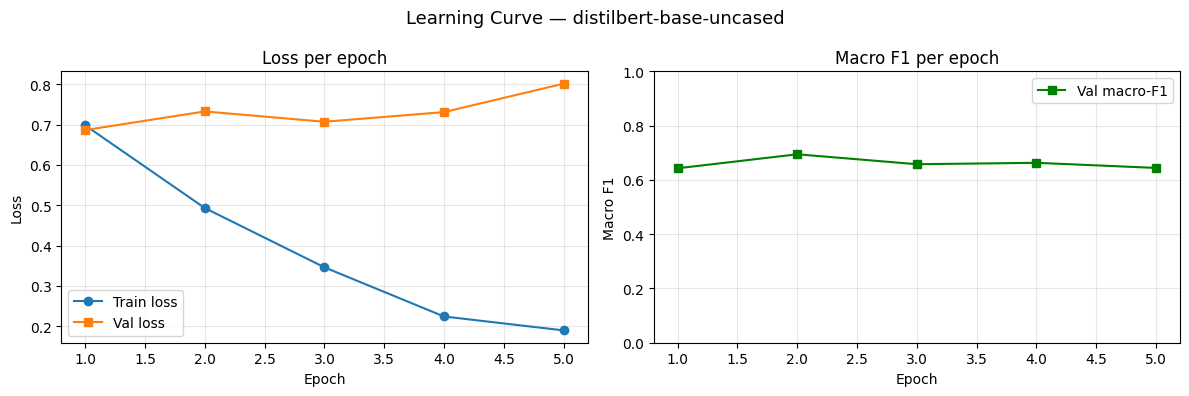

Saved: distilbert-base-uncased_learning_curve.png



=== distilbert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.933     0.782     0.851       551
   Interpret      0.910     0.975     0.941      2720
      Reveal      0.958     0.889     0.922      1648
      Revise      0.858     0.894     0.876       350

    accuracy                          0.922      5269
   macro avg      0.915     0.885     0.897      5269
weighted avg      0.924     0.922     0.921      5269


=== distilbert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             431              88           26            6
true_Interpret              5            2651           30           34
true_Reveal                26             145         1465           12
true_Revise                 0              29            8          313


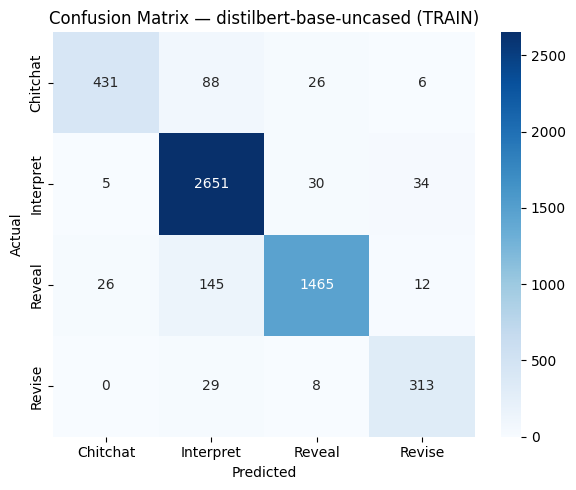


=== distilbert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.889     0.632     0.738        38
   Interpret      0.835     0.955     0.891       292
      Reveal      0.933     0.776     0.847       161
      Revise      0.375     0.250     0.300        12

    accuracy                          0.857       503
   macro avg      0.758     0.653     0.694       503
weighted avg      0.860     0.857     0.852       503


=== distilbert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              24              12            2            0
true_Interpret              3             279            6            4
true_Reveal                 0              35          125            1
true_Revise                 0               8            1            3


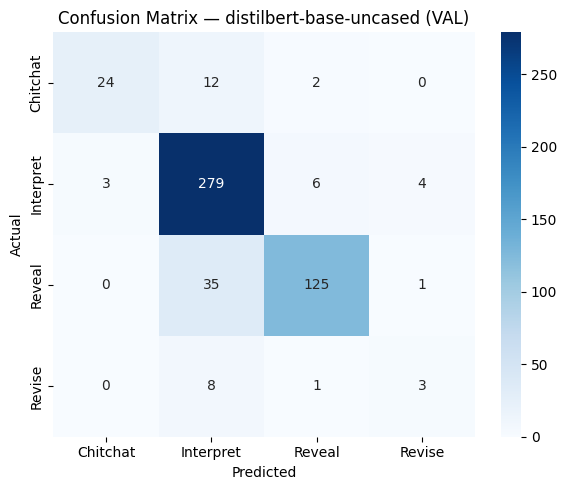


=== distilbert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,35
1,Chitchat,Interpret,12
2,Revise,Interpret,8
3,Interpret,Reveal,6
4,Interpret,Revise,4
5,Interpret,Chitchat,3
6,Chitchat,Reveal,2
7,Reveal,Revise,1
8,Revise,Reveal,1



=== distilbert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Interpret
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
37,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat



=== distilbert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.872     0.630     0.731        54
   Interpret      0.839     0.962     0.896       391
      Reveal      0.891     0.746     0.812       197
      Revise      0.300     0.150     0.200        20

    accuracy                          0.846       662
   macro avg      0.725     0.622     0.660       662
weighted avg      0.841     0.846     0.837       662


=== distilbert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              34              14            6            0
true_Interpret              1             376            8            6
true_Reveal                 4              45          147            1
true_Revise                 0              13            4            3


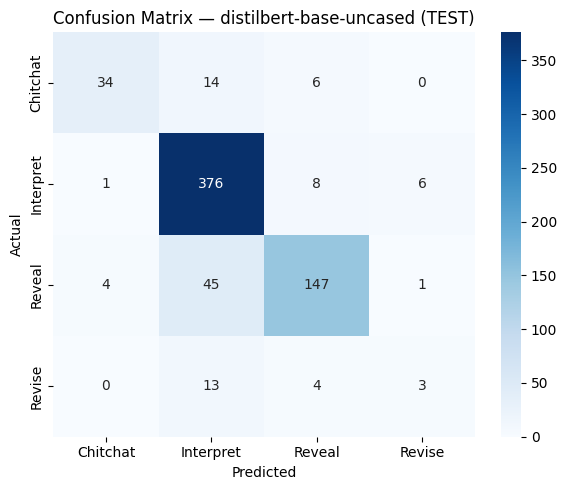


=== distilbert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,45
1,Chitchat,Interpret,14
2,Revise,Interpret,13
3,Interpret,Reveal,8
4,Chitchat,Reveal,6
5,Interpret,Revise,6
6,Revise,Reveal,4
7,Reveal,Chitchat,4
8,Interpret,Chitchat,1
9,Reveal,Revise,1



=== distilbert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
32,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Revise



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,distilbert-base-uncased,0.922376,0.914659,0.885022,0.897489,0.923998,0.922376,0.921493,5269,0.850938,551,0.941239,2720,0.922254,1648,0.875524,350
1,VAL,distilbert-base-uncased,0.856859,0.758014,0.653364,0.694323,0.859603,0.856859,0.851657,503,0.738462,38,0.891374,292,0.847458,161,0.300000,12
2,TEST,distilbert-base-uncased,0.845921,0.725497,0.621865,0.659911,0.841007,0.845921,0.836758,662,0.731183,54,0.896305,391,0.812155,197,0.200000,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/distilbert-base-uncased_all_split_metrics.csv


In [31]:
distilbert_trainer = run_model("distilbert-base-uncased", num_epochs=5)

## RoBERTa-base


  MODEL: roberta-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/roberta-base_results/checkpoint-3295
Best validation macro-F1: 0.6483813880040294


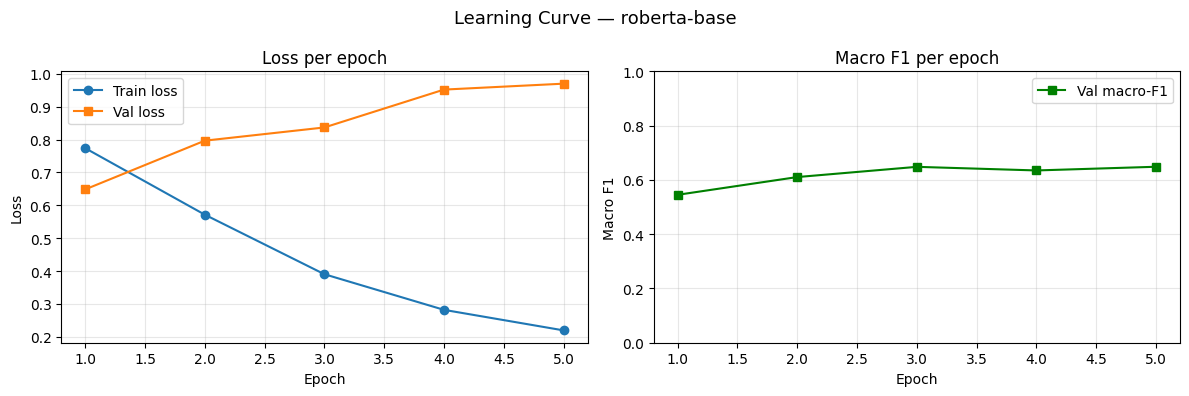

Saved: roberta-base_learning_curve.png



=== roberta-base — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.927     0.949     0.938       551
   Interpret      0.982     0.978     0.980      2720
      Reveal      0.975     0.964     0.969      1648
      Revise      0.924     0.969     0.946       350

    accuracy                          0.970      5269
   macro avg      0.952     0.965     0.958      5269
weighted avg      0.970     0.970     0.970      5269


=== roberta-base — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             523              17           11            0
true_Interpret              9            2660           25           26
true_Reveal                32              26         1588            2
true_Revise                 0               6            5          339


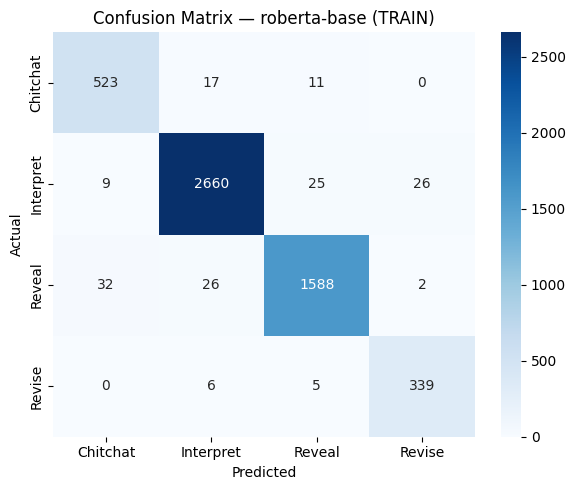


=== roberta-base — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.592     0.763     0.667        38
   Interpret      0.893     0.890     0.892       292
      Reveal      0.864     0.826     0.844       161
      Revise      0.222     0.167     0.190        12

    accuracy                          0.843       503
   macro avg      0.643     0.662     0.648       503
weighted avg      0.845     0.843     0.843       503


=== roberta-base — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              29               7            2            0
true_Interpret             11             260           17            4
true_Reveal                 8              17          133            3
true_Revise                 1               7            2            2


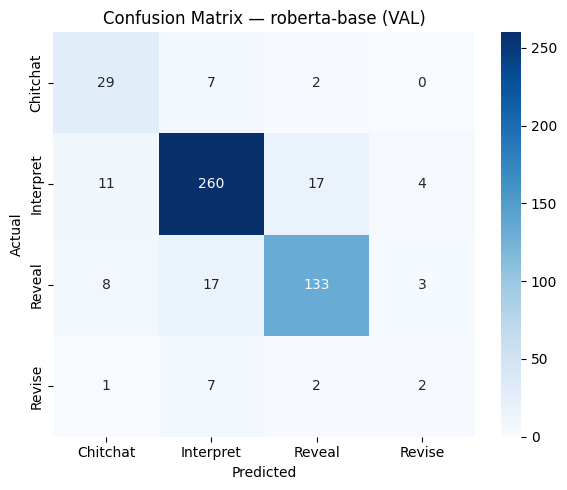


=== roberta-base VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,17
1,Reveal,Interpret,17
2,Interpret,Chitchat,11
3,Reveal,Chitchat,8
4,Chitchat,Interpret,7
5,Revise,Interpret,7
6,Interpret,Revise,4
7,Reveal,Revise,3
8,Chitchat,Reveal,2
9,Revise,Reveal,2



=== roberta-base VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Interpret
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Chitchat
40,USER: hi!,Interpret,Chitchat
46,USER: GOOD afternoone\nSYSTEM: GOOD afternoone...,Reveal,Interpret
50,"USER: Hello, I would like a child chair\nSYSTE...",Interpret,Revise
52,"USER: Hello, I would like a child chair\nSYSTE...",Interpret,Chitchat



=== roberta-base — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.650     0.722     0.684        54
   Interpret      0.883     0.905     0.894       391
      Reveal      0.832     0.807     0.820       197
      Revise      0.200     0.100     0.133        20

    accuracy                          0.837       662
   macro avg      0.641     0.634     0.633       662
weighted avg      0.828     0.837     0.832       662


=== roberta-base — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              39               9            5            1
true_Interpret             14             354           18            5
true_Reveal                 6              30          159            2
true_Revise                 1               8            9            2


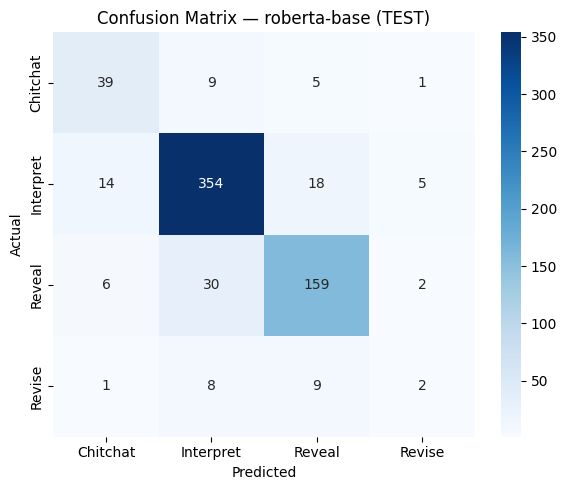


=== roberta-base TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,30
1,Interpret,Reveal,18
2,Interpret,Chitchat,14
3,Chitchat,Interpret,9
4,Revise,Reveal,9
5,Revise,Interpret,8
6,Reveal,Chitchat,6
7,Chitchat,Reveal,5
8,Interpret,Revise,5
9,Reveal,Revise,2



=== roberta-base TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Chitchat
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
33,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Chitchat



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,roberta-base,0.969823,0.951939,0.964822,0.958206,0.970120,0.969823,0.969911,5269,0.938117,551,0.979923,2720,0.969179,1648,0.945607,350
1,VAL,roberta-base,0.842942,0.642792,0.661581,0.648381,0.845120,0.842942,0.842983,503,0.666667,38,0.891938,292,0.844444,161,0.190476,12
2,TEST,roberta-base,0.836858,0.641313,0.633675,0.632768,0.828198,0.836858,0.831727,662,0.684211,54,0.893939,391,0.819588,197,0.133333,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/roberta-base_all_split_metrics.csv


In [32]:
roberta_trainer = run_model("roberta-base", num_epochs=5)

## BERT-base-uncased


  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Best checkpoint: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/bert-base-uncased_results/checkpoint-1977
Best validation macro-F1: 0.7493414936799379


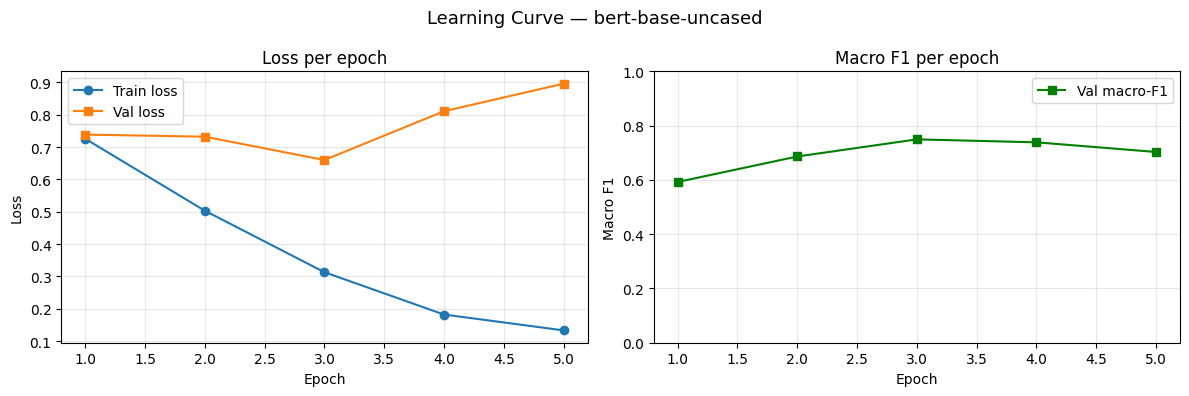

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.936     0.933     0.935       551
   Interpret      0.981     0.968     0.974      2720
      Reveal      0.965     0.964     0.964      1648
      Revise      0.879     0.974     0.924       350

    accuracy                          0.964      5269
   macro avg      0.940     0.960     0.949      5269
weighted avg      0.964     0.964     0.964      5269


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             514              21           15            1
true_Interpret             12            2633           39           36
true_Reveal                23              26         1589           10
true_Revise                 0               5            4          341


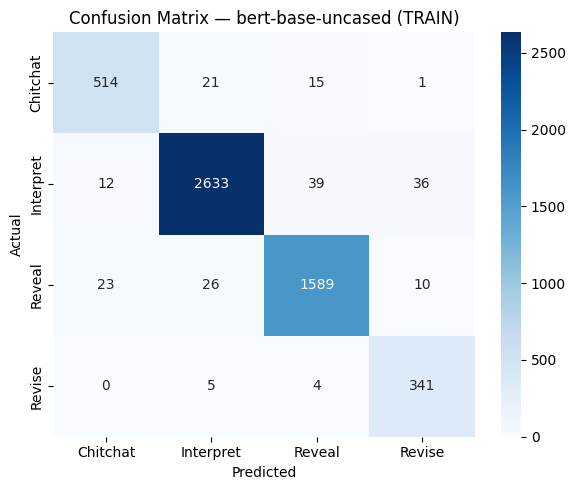


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.757     0.737     0.747        38
   Interpret      0.888     0.897     0.893       292
      Reveal      0.853     0.863     0.858       161
      Revise      0.625     0.417     0.500        12

    accuracy                          0.863       503
   macro avg      0.781     0.729     0.749       503
weighted avg      0.861     0.863     0.861       503


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              28               7            3            0
true_Interpret              8             262           19            3
true_Reveal                 1              21          139            0
true_Revise                 0               5            2            5


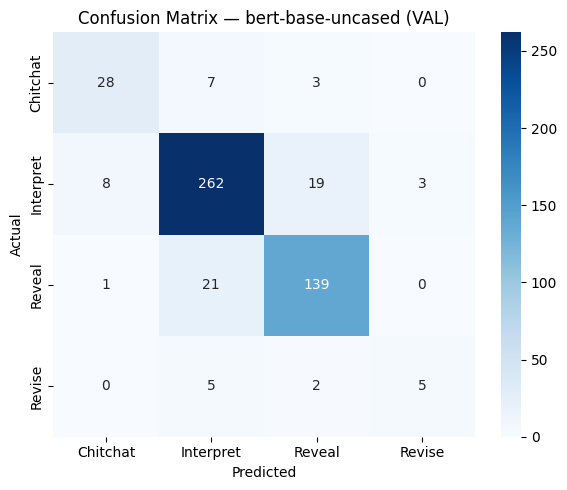


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,21
1,Interpret,Reveal,19
2,Interpret,Chitchat,8
3,Chitchat,Interpret,7
4,Revise,Interpret,5
5,Interpret,Revise,3
6,Chitchat,Reveal,3
7,Revise,Reveal,2
8,Reveal,Chitchat,1



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
6,USER: I want to buy a bicycle\nSYSTEM: How abo...,Interpret,Reveal
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Revise
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
37,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat
46,USER: GOOD afternoone\nSYSTEM: GOOD afternoone...,Reveal,Interpret
54,"USER: Hello, I would like a stereo\nSYSTEM: Pr...",Interpret,Reveal



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.736     0.722     0.729        54
   Interpret      0.897     0.916     0.906       391
      Reveal      0.870     0.848     0.859       197
      Revise      0.167     0.150     0.158        20

    accuracy                          0.856       662
   macro avg      0.667     0.659     0.663       662
weighted avg      0.854     0.856     0.855       662


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              39               8            7            0
true_Interpret              9             358           12           12
true_Reveal                 3              24          167            3
true_Revise                 2               9            6            3


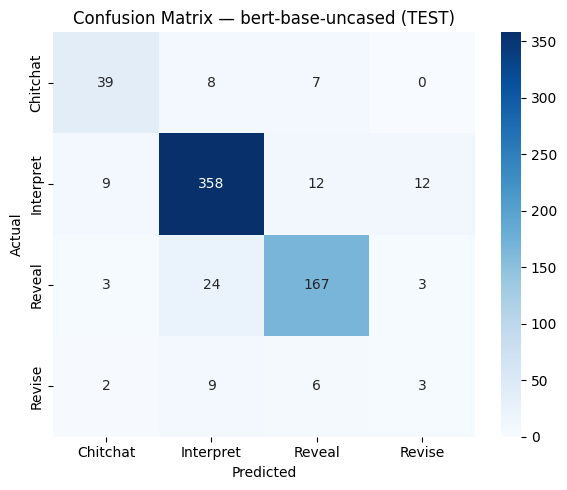


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,24
1,Interpret,Reveal,12
2,Interpret,Revise,12
3,Interpret,Chitchat,9
4,Revise,Interpret,9
5,Chitchat,Interpret,8
6,Chitchat,Reveal,7
7,Revise,Reveal,6
8,Reveal,Chitchat,3
9,Reveal,Revise,3



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Revise
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
32,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Revise



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,bert-base-uncased,0.963560,0.940133,0.959837,0.949360,0.964275,0.963560,0.963733,5269,0.934545,551,0.974283,2720,0.964492,1648,0.924119,350
1,VAL,bert-base-uncased,0.862823,0.780663,0.728531,0.749341,0.860610,0.862823,0.861185,503,0.746667,38,0.892675,292,0.858025,161,0.500000,12
2,TEST,bert-base-uncased,0.856495,0.667388,0.658885,0.662952,0.853837,0.856495,0.855051,662,0.728972,54,0.906329,391,0.858612,197,0.157895,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/bert-base-uncased_all_split_metrics.csv


In [30]:
bert_trainer = run_model("bert-base-uncased", num_epochs=5)

## MiniLM


  MODEL: microsoft/MiniLM-L12-H384-uncased


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/MiniLM-L12-H384-uncased_results/checkpoint-1318
Best validation macro-F1: 0.6169585134721436


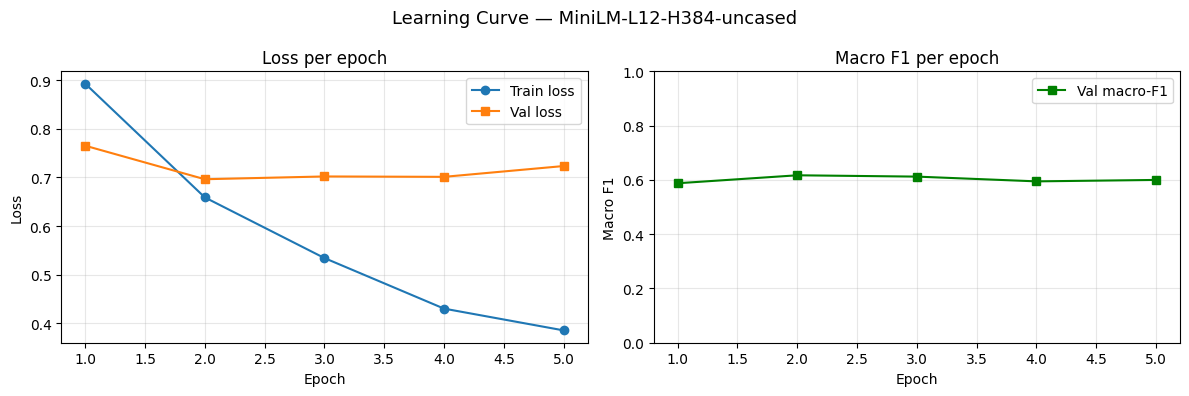

Saved: minilm-l12-h384-uncased_learning_curve.png



=== MiniLM-L12-H384-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.956     0.668     0.786       551
   Interpret      0.852     0.978     0.910      2720
      Reveal      0.954     0.862     0.906      1648
      Revise      0.861     0.671     0.754       350

    accuracy                          0.889      5269
   macro avg      0.906     0.795     0.839      5269
weighted avg      0.895     0.889     0.886      5269


=== MiniLM-L12-H384-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             368             148           32            3
true_Interpret              3            2660           26           31
true_Reveal                14             210         1420            4
true_Revise                 0             105           10          235


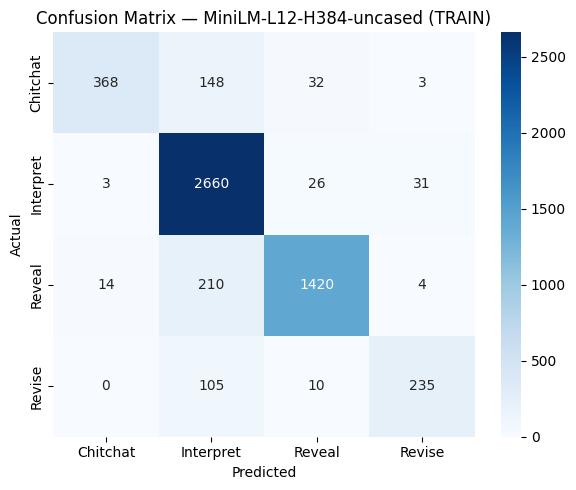


=== MiniLM-L12-H384-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.958     0.605     0.742        38
   Interpret      0.821     0.973     0.890       292
      Reveal      0.931     0.758     0.836       161
      Revise      0.000     0.000     0.000        12

    accuracy                          0.853       503
   macro avg      0.678     0.584     0.617       503
weighted avg      0.847     0.853     0.840       503


=== MiniLM-L12-H384-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              23              13            2            0
true_Interpret              1             284            6            1
true_Reveal                 0              38          122            1
true_Revise                 0              11            1            0


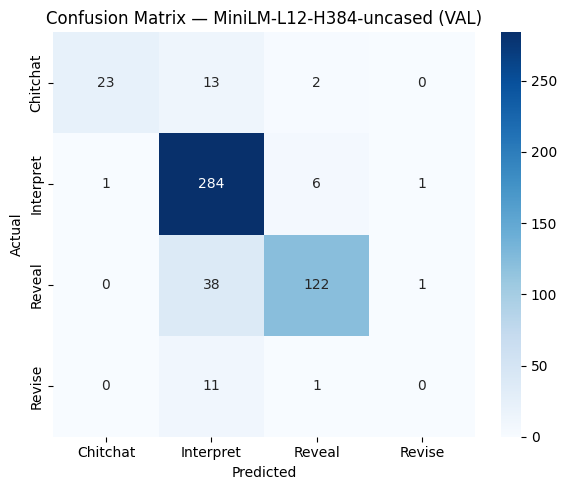


=== MiniLM-L12-H384-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,38
1,Chitchat,Interpret,13
2,Revise,Interpret,11
3,Interpret,Reveal,6
4,Chitchat,Reveal,2
5,Interpret,Revise,1
6,Interpret,Chitchat,1
7,Reveal,Revise,1
8,Revise,Reveal,1



=== MiniLM-L12-H384-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Interpret
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
37,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat



=== MiniLM-L12-H384-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.972     0.648     0.778        54
   Interpret      0.835     0.982     0.902       391
      Reveal      0.915     0.761     0.831       197
      Revise      0.000     0.000     0.000        20

    accuracy                          0.860       662
   macro avg      0.680     0.598     0.628       662
weighted avg      0.845     0.860     0.844       662


=== MiniLM-L12-H384-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              35              15            4            0
true_Interpret              0             384            6            1
true_Reveal                 1              45          150            1
true_Revise                 0              16            4            0


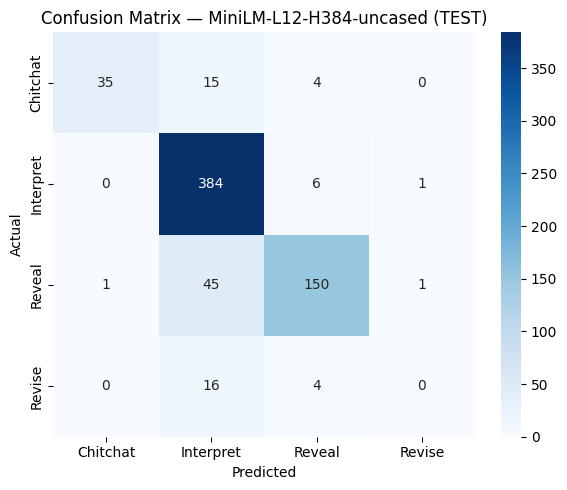


=== MiniLM-L12-H384-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,45
1,Revise,Interpret,16
2,Chitchat,Interpret,15
3,Interpret,Reveal,6
4,Chitchat,Reveal,4
5,Revise,Reveal,4
6,Interpret,Revise,1
7,Reveal,Chitchat,1
8,Reveal,Revise,1



=== MiniLM-L12-H384-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,MiniLM-L12-H384-uncased,0.888783,0.905674,0.794724,0.839211,0.895310,0.888783,0.885613,5269,0.786325,551,0.910491,2720,0.905612,1648,0.754414,350
1,VAL,MiniLM-L12-H384-uncased,0.852883,0.677610,0.583907,0.616959,0.846982,0.852883,0.840338,503,0.741935,38,0.890282,292,0.835616,161,0.000000,12
2,TEST,MiniLM-L12-H384-uncased,0.859517,0.680410,0.597917,0.627818,0.844536,0.859517,0.843772,662,0.777778,54,0.902468,391,0.831025,197,0.000000,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/4classFinalscript_noleaknew/MiniLM-L12-H384-uncased_all_split_metrics.csv


In [33]:
minilm_trainer = run_model("microsoft/MiniLM-L12-H384-uncased", num_epochs=5)

## DeBERTa-v3-base

> **Note:** Run the cell below before this model if sentencepiece is not installed.
> ```
> !pip install sentencepiece -q
> ```

In [ ]:
#!pip install sentencepiece -q


In [ ]:
#deberta_trainer = run_model("microsoft/deberta-v3-base", num_epochs=5)

**Inference check**

In [36]:
def get_trainer(x):
    # If x is (trainer, metrics), return trainer
    if isinstance(x, tuple):
        return x[0]
    return x

bert_trainer = get_trainer(bert_trainer)
distilbert_trainer = get_trainer(distilbert_trainer)
roberta_trainer = get_trainer(roberta_trainer)
minilm_trainer = get_trainer(minilm_trainer)

print(type(bert_trainer))
print(type(distilbert_trainer))
print(type(roberta_trainer))
print(type(minilm_trainer))

<class '__main__.WeightedTrainer'>
<class '__main__.WeightedTrainer'>
<class '__main__.WeightedTrainer'>
<class '__main__.WeightedTrainer'>


In [37]:
import time
import pandas as pd

runtime_rows = []

models_to_check = [
    ("BERT Base", "bert-base-uncased", bert_trainer),
    ("DistilBERT", "distilbert-base-uncased", distilbert_trainer),
    ("RoBERTa", "roberta-base", roberta_trainer),
    ("MiniLM", "microsoft/MiniLM-L12-H384-uncased", minilm_trainer),
]

for display_name, hf_model_name, trainer in models_to_check:

    use_fast = False if "deberta-v3" in hf_model_name else True
    tokenizer = AutoTokenizer.from_pretrained(hf_model_name, use_fast=use_fast)

    _, _, test_ds_for_model = make_hf_datasets(
        tokenizer,
        X_train, y_train_ids,
        X_val, y_val_ids,
        X_test, y_test_ids,
    )

    start = time.time()
    _ = trainer.predict(test_ds_for_model)
    end = time.time()

    total_time = end - start
    avg_time = total_time / len(X_test)

    runtime_rows.append({
        "model": display_name,
        "hf_model_name": hf_model_name,
        "test_samples": len(X_test),
        "total_inference_sec": round(total_time, 3),
        "avg_inference_per_sample_sec": round(avg_time, 5),
    })

runtime_df = pd.DataFrame(runtime_rows)
display(runtime_df)

runtime_df.to_csv(
    os.path.join(RESULTS_DIR, "model_inference_runtime.csv"),
    index=False,
)

,model,hf_model_name,test_samples,total_inference_sec,avg_inference_per_sample_sec
0,BERT Base,bert-base-uncased,662,1.526,0.00230
1,DistilBERT,distilbert-base-uncased,662,0.911,0.00138
2,RoBERTa,roberta-base,662,1.495,0.00226
3,MiniLM,microsoft/MiniLM-L12-H384-uncased,662,1.521,0.00230
